# MEC spikes → LFADS model → latent factors

Use **lfads-torch's native `run_model`** for model creation, training, checkpoint selection, and posterior inference. The helpers only prepare native input and export timestamped factors. No downstream analyses are included.

First create the separate **Python 3.10** environment described in `README.md` and select its **LFADS MEC** kernel. The pinned upstream LFADS implementation uses older PyTorch/Lightning versions than the CEBRA environment.

The default input remains **120 Hz raw spike counts**. LFADS returns a factor vector for **every included bin**, with no output subsampling. Its bidirectional encoders use the complete one-second sequence; this is the inference context, not a one-second averaging filter.

In [17]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import os

import numpy as np

from mec_data import bin_spikes, load_mec_spikes
from mec_lfads import export_lfads_latent, write_lfads_data

DATA_PATH = Path("/stelmo/sam/tmp/27765_2.mat")
WORK_DIR = Path("results/lfads").resolve()
DATA_FILE = WORK_DIR / "mec.h5"
RUN_DIR = WORK_DIR / "test"

BIN_SECONDS = 1 / 120
SEQUENCE_SECONDS = 1.0
FACTOR_DIM = 16
BATCH_SIZE = 64
MAX_EPOCHS = 300
POSTERIOR_SAMPLES = 50

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Prepare native LFADS input

Use the same units and binning as CEBRA. Fixed-length, nonoverlapping sequences stay within uninterrupted intervals. Short intervals and incomplete final sequences are omitted, without padding or joining across gaps. The helper reports the excluded bins.

The last 20% of eligible intervals are reserved for validation; each complete interval belongs to one split. This validation split selects the checkpoint and is not a separate test set. Use a new `WORK_DIR` for a new run.

For your own already-binned data, provide `count_blocks` shaped `(n_bins_in_interval, n_units)` and matching `time_blocks` shaped `(n_bins_in_interval,)` directly.

In [16]:
spikes, intervals = load_mec_spikes(DATA_PATH)
count_blocks, time_blocks = bin_spikes(
    spikes, intervals, bin_seconds=BIN_SECONDS, min_bins=1
)
sequence_bins = round(SEQUENCE_SECONDS / BIN_SECONDS)
summary = write_lfads_data(
    count_blocks,
    time_blocks,
    DATA_FILE,
    sequence_bins=sequence_bins,
    valid_fraction=0.2,
)
print(summary)

{'n_units': 460, 'sequence_bins': 120, 'n_train': 896, 'n_valid': 207, 'included_bins': 132360, 'omitted_bins': 22996}


## 2. Create, train, and infer with lfads-torch

The bundled `nlb_mc_maze` spiking model supplies the Poisson observation model, encoder, generator, controller, coordinated dropout, priors, optimizer, and regularization. Overrides below set the data dimensions, factor dimension, and run settings. The native runner trains the model, selects the best validation checkpoint, and averages posterior outputs over `POSTERIOR_SAMPLES` draws.

The `callbacks=[]` override disables the optional raster/trajectory plotting configuration; native checkpointing, early stopping, and training logs remain active. The posterior file contains factors, inferred activity, and other native model outputs.

In [18]:
from lfads_torch.run_model import run_model

overrides = {
    "model": "nlb_mc_maze",
    "datamodule": "nlb_mc_maze",
    "callbacks": [],
    "datamodule.datafile_pattern": str(DATA_FILE),
    "datamodule.batch_keys": [],
    "datamodule.attr_keys": [],
    "datamodule.batch_size": min(BATCH_SIZE, summary["n_train"]),
    "model.encod_data_dim": summary["n_units"],
    "model.encod_seq_len": sequence_bins,
    "model.recon_seq_len": sequence_bins,
    "model.fac_dim": FACTOR_DIM,
    "model.readout.modules.0.out_features": summary["n_units"],
    "trainer.max_epochs": MAX_EPOCHS,
    "posterior_sampling.fn.num_samples": POSTERIOR_SAMPLES,
}

RUN_DIR.mkdir(parents=True, exist_ok=True)
if any(RUN_DIR.iterdir()):
    raise FileExistsError("Use an empty RUN_DIR to preserve previous results.")
(RUN_DIR / "overrides.json").write_text(
    json.dumps(overrides, indent=2), encoding="utf-8"
)

original_directory = Path.cwd()
try:
    os.chdir(RUN_DIR)
    run_model(overrides=overrides)
finally:
    os.chdir(original_directory)

Global seed set to 0
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7,8,9]

  | Name             | Type                             | Params
----------------------------------------------------------------------
0 | encoder          | Encoder                          | 420 K 
1 | decoder          | Decoder                          | 180 K 
2 | readout          | ModuleList                       | 7.8 K 
3 | ic_prior         | MultivariateNormal               | 128   
4 | co_prior         | AutoregressiveMultivariateNormal | 8     
5 | valid_recon_smth | ExpSmoothedMetric                | 0     
----------------------------------------------------------------------
607 K     Trainable params
1.6 K     Non-trainable params
609 K     Total params
2.438     Total estimated model params size (MB)


Epoch 299: 100%|██████████| 18/18 [56:42<00:00, 189.04s/it, loss=672, v_num=]   


100%|██████████| 4/4 [00:34<00:00,  8.72s/it]


## 3. Export native latent factors

`latent` contains LFADS's **posterior-averaged factors**, not the higher-dimensional generator states or per-neuron inferred activity. No PCA, interpolation, smoothing, or stitching is applied. Timestamp, interval, sequence, and train/validation labels remain available for your downstream analysis.

The dynamics reset between sequences. Preserve `sequence_id` when computing time-series analyses, even when successive sequences belong to the same continuous interval.

In [19]:
POSTERIOR_FILE = RUN_DIR / f"lfads_output_{DATA_FILE.stem}.h5"
RESULTS_FILE = WORK_DIR / "lfads_latent.npz"

results = export_lfads_latent(
    POSTERIOR_FILE, RESULTS_FILE, bin_seconds=BIN_SECONDS
)
latent = results["latent"]  # (n_included_bins, n_factors)
time = results["time"]  # (n_included_bins,), seconds
segment_id = results["segment_id"]
sequence_id = results["sequence_id"]
print(f"Saved latent {latent.shape} to {RESULTS_FILE}")

Saved latent (132360, 16) to /home/sambray/Documents/mec_lfads_pipeline/results/lfads/lfads_latent.npz


## Reload results

The native model checkpoints are under `RUN_DIR / "lightning_checkpoints"`. `lfads-torch.run_model` accepts a `checkpoint_dir` argument to restore a model for further training or posterior inference; it selects the most recently written checkpoint in that directory. The posterior file above was generated from the best validation checkpoint.

In [9]:
with np.load(RESULTS_FILE, allow_pickle=False) as saved:
    latent = saved["latent"]
    time = saved["time"]
    segment_id = saved["segment_id"]
    sequence_id = saved["sequence_id"]
    split = saved["split"]  # 0: training, 1: validation.

print(f"Latent: {latent.shape}; timestamps: {time.shape}")

Latent: (132360, 16); timestamps: (132360,)


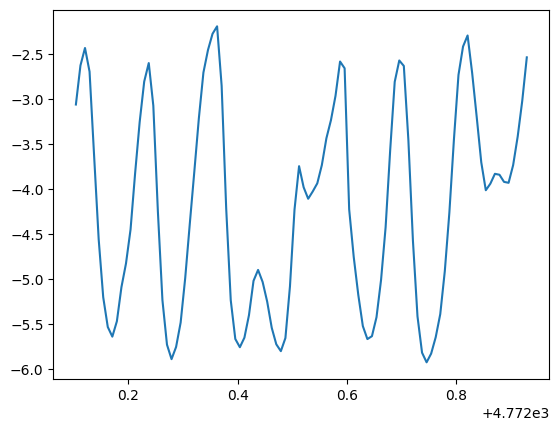

In [13]:
st = 10_500
ind = slice(st,st+100)

import matplotlib.pyplot as plt
plt.plot(time[ind], latent[ind, 0], label="Factor 0")

In [14]:
np.diff(time[ind])

array([0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833333,
       0.00833333, 0.00833333, 0.00833333, 0.00833333, 0.00833